In [ ]:
import os
import os.path as op

import matplotlib.pyplot as plt

import holoviews as hv
from holoviews import dim, opts
import pandas as pd

import hnn_core
from hnn_core.params import _short_name

from hnn_core import human_ET_model, simulate_dipole, read_dipole, MPIBackend, jones_2009_model


from hnn_core.optimization import Optimizer
import numpy as np
hnn_core_root = op.join(op.dirname(hnn_core.__file__))
pathfig = '/Users/katharinaduecker/Documents/projects_brown/hnn-tuning/new_model_HNN/figures/'

# The number of cores may need modifying depending on your current machine.
n_procs = 10
cols = np.array(([27, 158, 119], [217,95,2], [117,112,179], [231,41,138], [102,166,30]))/255
plt.rcParams['pdf.fonttype'] = 'truetype'

# Set global font sizes
plt.rcParams['font.size'] = 12          # Default text size
plt.rcParams['axes.titlesize'] = 12      # Title size
plt.rcParams['axes.labelsize'] = 12      # Axis labels (xlabel, ylabel)
plt.rcParams['xtick.labelsize'] = 12    # X-axis tick labels
plt.rcParams['ytick.labelsize'] = 12     # Y-axis tick labels
plt.rcParams['legend.fontsize'] = 12     # Legend text

ModuleNotFoundError: No module named 'holoviews'

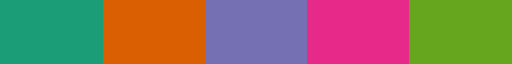

In [2]:
def assign_color(gid):
    for cell_type, gid_range in net_hand.gid_ranges.items():
        if cell_type in list(cell_type_colors.keys()):
            if gid in gid_range:
                return cell_type_colors[cell_type]
            
from cmcrameri import cm
import matplotlib
step_cm = int(len(cm.hawaiiS.colors) / 19)
cm_neurons = np.array([[166,206,227], [31,120,180], [178,223,138],[51,160,44]])/255


cmap = matplotlib.colors.ListedColormap(cm_neurons)

col_lines = np.array(([27, 158, 119], [217,95,2], [117,112,179], [231,41,138], [102,166,30]))/255
cmap_lines = matplotlib.colors.ListedColormap(col_lines)
cmap_lines

In [3]:
exp_dpl = read_dipole('/Users/katharinaduecker/Documents/projects_brown/hnn-data/MEG_detection_data/S1_SupraT.txt')

In [11]:
depths

[np.float64(-50.0),
 np.float64(-36.241610738255034),
 np.float64(-22.483221476510067),
 np.float64(-8.724832214765101),
 np.float64(5.033557046979865),
 np.float64(18.79194630872483),
 np.float64(32.5503355704698),
 np.float64(46.308724832214764),
 np.float64(60.06711409395973),
 np.float64(73.8255033557047),
 np.float64(87.58389261744966),
 np.float64(101.34228187919462),
 np.float64(115.1006711409396),
 np.float64(128.85906040268458),
 np.float64(142.61744966442953),
 np.float64(156.37583892617448),
 np.float64(170.13422818791946),
 np.float64(183.89261744966444),
 np.float64(197.6510067114094),
 np.float64(211.40939597315435),
 np.float64(225.16778523489933),
 np.float64(238.9261744966443),
 np.float64(252.68456375838923),
 np.float64(266.4429530201342),
 np.float64(280.2013422818792),
 np.float64(293.9597315436242),
 np.float64(307.71812080536915),
 np.float64(321.4765100671141),
 np.float64(335.23489932885906),
 np.float64(348.99328859060404),
 np.float64(362.75167785234896),
 np

In [ ]:
# handtune a little bit
net_hand = human_ET_model(mesh_shape=(1,1))
net_hand.set_cell_positions(inplane_distance=30.)
net_hand.clear_connectivity()

synaptic_delays_p = {'L2_basket': 0.1, 'L2_pyramidal': 0.1,
                     'L5_basket': 1., 'L5_pyramidal': 1.}
synaptic_delays_d = {'L2_basket': 0.1, 'L2_pyramidal': 0.1, 'L5_pyramidal': 1.}

depths = list(list(range(-50,2500,150)))
electrode_pos = [(1, 1, dep) for dep in depths]
net_hand.add_electrode_array('probe1', electrode_pos, method='psa')

prox1_weights_ampa = {'L2_basket': 0,#0.012001631896723274*0.001,
                        'L2_pyramidal': 0,#.5,
                        'L5_basket': 0,#0.009887830212563252*0.001,
                        'L5_pyramidal': 0.00177625254823576}
prox1_weights_nmda = {'L2_basket': 0,#0.0001933186741151145,
                        'L2_pyramidal': 0,#0.0016930670528282604,
                        'L5_basket': 0,#0.004778468815158654*0.001,
                        'L5_pyramidal': 0.0013377943754119702*0.001}

net_hand.add_evoked_drive('prox1',
                        mu = 16,
                        sigma = 2,
                        numspikes = 1,
                        location = 'proximal',
                        weights_ampa = prox1_weights_ampa,
                        weights_nmda = prox1_weights_nmda,
                        synaptic_delays = synaptic_delays_p, event_seed=544)
# Distal

dist_weights_ampa = {'L2_basket': 0,#0.0015856138634223072,
                    'L2_pyramidal': 0,#0.002,
                    'L5_pyramidal': .02}
dist_weights_nmda = {'L2_basket': 0,#0.09312719515251287,
                    'L2_pyramidal': 0,#0.002,
                    'L5_pyramidal': .02}

synaptic_delays_d = {'L2_basket': 0.1, 'L2_pyramidal': 0.1, 'L5_pyramidal': 1.}
net_hand.add_evoked_drive('dist',
                        mu = 55,
                        sigma = 2,
                        numspikes = 2,
                        location = 'distal',
                        weights_ampa = dist_weights_ampa,
                        weights_nmda = dist_weights_nmda,
                        synaptic_delays = synaptic_delays_d, event_seed=544)

# Proximal 2
prox2_weights_ampa = {'L2_basket': 0,#0.006622737231283097,
                        'L2_pyramidal': 0,#0.750791266899394,
                        'L5_basket': 0,#0.02229356628634976,
                        'L5_pyramidal': 0.12744892823619833}
prox2_weights_nmda = {'L2_basket': 0,#0.012973495518022455,
                    'L2_pyramidal': 0,#0.022802318835492184,
                    'L5_basket': 0,#0.00422401301129021,
                    'L5_pyramidal': 0.23612697575815428}

net_hand.add_evoked_drive('prox2',
                        mu = 91.5,
                        sigma = 5.5,
                        numspikes = 13,
                        location = 'proximal',
                        weights_ampa = prox2_weights_ampa,
                        weights_nmda = prox2_weights_nmda,
                        synaptic_delays = synaptic_delays_p, event_seed=544)

# Simulate the optimized model
tstop = exp_dpl.times[-1]
smooth_window_len = 10

# with MPIBackend(n_procs=n_procs, mpi_cmd='mpiexec'):
hand_dpl = simulate_dipole(net_hand, tstop=tstop, n_trials=1,bsl_cor='calcium', record_vsec='all', record_isec='all')[0]

scale_factor = 1000  
hand_dpl.scale(scale_factor).smooth(smooth_window_len)
from hnn_core.dipole import _rmse

hand_rmse = _rmse(hand_dpl, exp_dpl,tstart=0,tstop=1000)

from hnn_core.extracellular import _get_laminar_z_coords, calculate_csd2d

contact_labels, delta = _get_laminar_z_coords(net_hand.rec_arrays['probe1'][0].positions)
new_lim = contact_labels[0:len(contact_labels):2]/1000




Joblib will run 1 trial(s) in parallel by distributing trials over 1 jobs.
Building the NEURON model
Section start: [   0.            0.         1045.92004395] Section end: [   0.            0.         1065.92004395]
Section: L2Basket_soma electrode at (1, 1, -50):
transfer resistance: [0.2398528]
Section start: [   0.            0.         1307.40002441] Section end: [   0.     0.  1329.5]
Section: L2Pyr_soma electrode at (1, 1, -50):
transfer resistance: [0.19383835]
Section start: [   0.     0.  1329.5] Section end: [   0.    0. 1389.]
Section: L2Pyr_apical_trunk electrode at (1, 1, -50):
transfer resistance: [0.18822644]
Section start: [   0.    0. 1389.] Section end: [-340.    0. 1389.]
Section: L2Pyr_apical_oblique electrode at (1, 1, -50):
transfer resistance: [0.18430662 0.18409276 0.18367153 0.18304719 0.18222594 0.18121579
 0.18002631]
Section start: [   0.    0. 1389.] Section end: [   0.    0. 1695.]
Section: L2Pyr_apical_1 electrode at (1, 1, -50):
transfer resistance: [0.

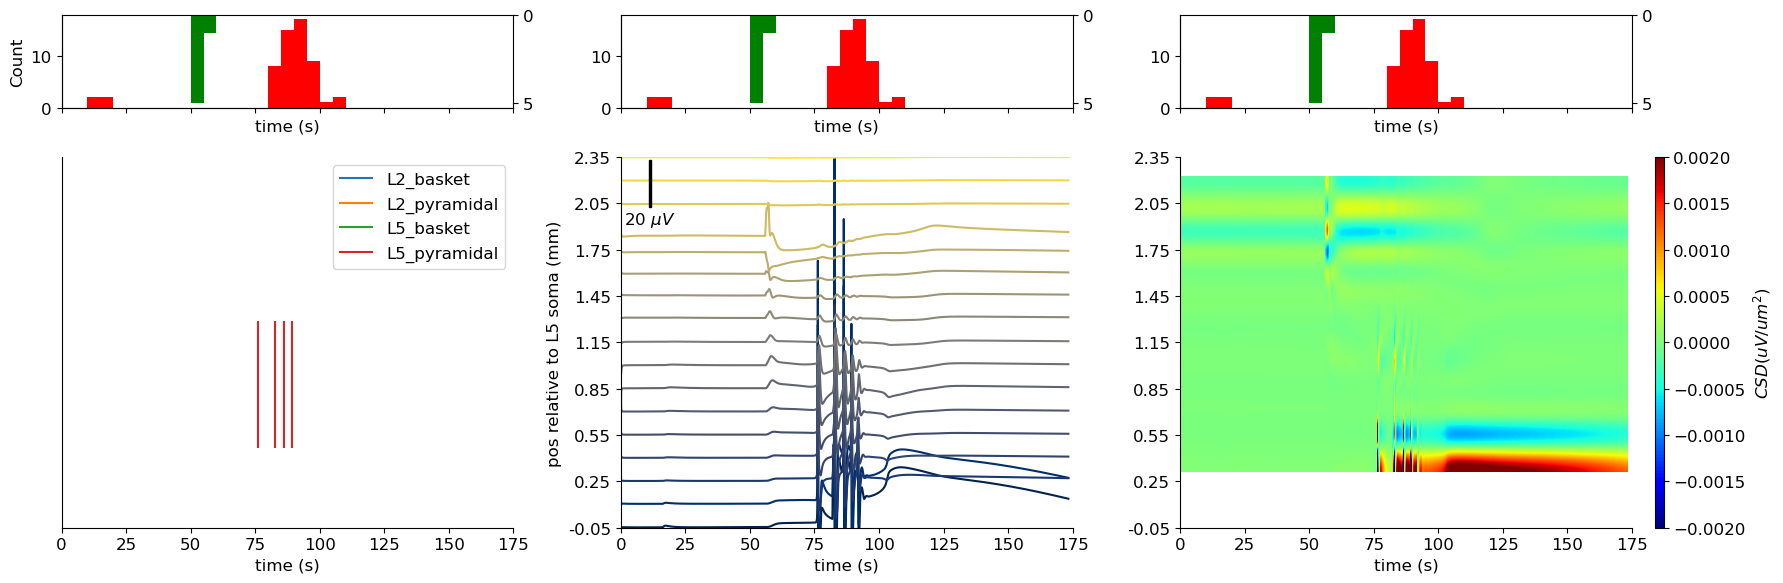

In [27]:
fig, ax = plt.subplots(2,3,figsize=(18,6), height_ratios=[0.25,1], sharex=True)

bins = np.arange(0, tstop, 5)  # histogram bins

# lfp = net_hand.rec_arrays['probe1'][0].voltages[0]
# drives
# proximal and distal histogram
spike_prox1 = np.array(net_hand.cell_response.spike_times_by_type['prox1']).reshape(-1,1)
spike_dist = np.array(net_hand.cell_response.spike_times_by_type['dist']).reshape(-1,1)
spike_prox2 = np.array(net_hand.cell_response.spike_times_by_type['prox2']).reshape(-1,1)

for i in range(3):
    ax[0,i].hist(spike_prox1, bins, color='r')
    #ax[0,i].set_ylim([0, 1500])

    if i == 0:
        ax[0,i].set_ylabel('Count')
    ax[0,i].hist(spike_prox2, bins, color='r')

    ax1tw = ax[0,i].twinx()
    ax1tw.hist(spike_dist, bins, color='g')
    #ax1tw.set_ylim([0, 1500])
    ax1tw.invert_yaxis()


# spiking
net_hand.cell_response.plot_spikes_raster(ax=ax[1,0], show=False)


#ax[1,2].plot(net_hand.cell_response.times, lfp.T, color='k', alpha=0.5)
net_hand.rec_arrays['probe1'][0].plot_lfp(ax=ax[1,1], show=False, voltage_offset=10, voltage_scalebar=20)
lfp_ticks = ax[1,1].get_yticks()
ax[1,1].set_yticks(np.linspace(lfp_ticks[0], lfp_ticks[-1], len(new_lim)))
ax[1,1].set_yticklabels(new_lim)
ax[1,1].set_ylabel('pos relative to L5 soma (mm)')
ax[1,1].set_ylim([lfp_ticks[0], lfp_ticks[-1]])

# lfp = net_hand.rec_arrays['probe1'][0].smooth(smooth_window_len)
# lfp = lfp.voltages[0]
# csd2d = np.zeros((lfp.shape[0]-4, lfp.shape[1]))
# for i in np.arange(2, lfp.shape[0]-2):
#     csd2d[i-2, :] = - (lfp[i-2, :] - 2 * lfp[i, :] + lfp[i+2, :]) / (delta*2 ** 2)

# n_offsets = csd2d.shape[0]
# trace_offsets = np.zeros((n_offsets, 1))
# voltage_offset=0.1
# trace_offsets = np.arange(n_offsets)[:, np.newaxis] * voltage_offset

# for i in range(csd2d.shape[0]):
#     ax[1,3].plot(net_hand.cell_response.times, csd2d[i, :] + trace_offsets[i], color='k', alpha=0.75)
#     sink_idx = csd2d[i,:] < 0
#     ax[1,3].fill_between(net_hand.cell_response.times[sink_idx], csd2d[i, sink_idx] + trace_offsets[i], + trace_offsets[i], color='k', alpha=0.25)

net_hand.rec_arrays['probe1'][0].plot_csd(ax=ax[1,2], show=False, vmin=-0.002, vmax=0.002)
csd_ticks = ax[1,2].get_yticks()
ax[1,2].set_yticks(np.linspace(csd_ticks[0], csd_ticks[-1], len(new_lim)))
ax[1,2].set_yticklabels(new_lim)
ax[1,2].set_ylabel('')

csd_ticks = ax[1,2].get_yticks()
ax[1,2].set_yticks(np.linspace(csd_ticks[0], csd_ticks[-1], len(new_lim)))
ax[1,2].set_yticklabels(new_lim)
ax[1,2].set_ylabel('')

ax = ax.flatten()
for a in ax:
    a.set_xlabel('time (s)')
    a.spines['top'].set_visible(False)
    a.spines['right'].set_visible(False)
    a.set_xticks(np.arange(0, 176, 25))
    a.set_xlim((0, 175))


fig.tight_layout()
fig.savefig(op.join(pathfig, 'l5_spiking_lfp_csd_all_layers.pdf'), bbox_inches='tight', dpi=300)
fig.savefig(op.join(pathfig, 'l5_spiking_lfp_csd_all_layers.png'), bbox_inches='tight', dpi=300)

In [ ]:
for pt in net_hand.cell_types['L2_pyramidal'].sections['soma'].end_pts:
    print(pt)

In [ ]:
lfp = net_hand.rec_arrays['probe1'][0].smooth(smooth_window_len)
lfp = lfp.voltages[0]
csd2d = np.zeros((lfp.shape[0]-2, lfp.shape[1]))
for i in np.arange(1, lfp.shape[0]-1):
    csd2d[i-1, :] = - (lfp[i-1, :] - 2 * lfp[i, :] + lfp[i+1, :]) / delta ** 2

n_offsets = csd2d.shape[0]
trace_offsets = np.zeros((n_offsets, 1))
voltage_offset=0.01
trace_offsets = np.arange(n_offsets)[:, np.newaxis] * voltage_offset

fig, ax = plt.subplots(1,2, figsize=(8, 6))
for i in range(csd2d.shape[0]):
    ax[0].plot(net_hand.cell_response.times, csd2d[i, :] + trace_offsets[i], color='k', alpha=0.75)
    sink_idx = csd2d[i,:] < 0
    ax[0].fill_between(net_hand.cell_response.times[sink_idx], csd2d[i, sink_idx] + trace_offsets[i], + trace_offsets[i], color='k', alpha=0.25)

ax[1].pcolormesh(csd2d, rasterized=True, cmap='jet', vmin=-0.001, vmax=0.001)
fig.savefig(os.path.join(pathfig,'csd2d.png'))
fig.savefig(os.path.join(pathfig,'csd2d.pdf'))

In [ ]:
net_hand.plot_cells()